# Multimodal AI-Based Pneumonia Detection: Classification, Localization & Future Biomarker Integration
### A Complete, End-to-End Medical Imaging Project for Kaggle GPU

---

## ðŸ“Œ Project Overview
Pneumonia is an acute inflammatory infection of the lung parenchyma, primarily confirmed using **Chest Radiographs (X-Rays)** in conjunction with patient symptoms and blood laboratory profiles. 

In this project, we implement a complete, beginner-friendly deep learning pipeline on the **RSNA Pneumonia Detection Challenge** dataset. The project is organized into two distinct, separated computer vision tasks and an architectural blueprint for future clinical multimodal fusion:

1. **Pneumonia Classification (Disease Screening):**
   - We construct a baseline **Custom Convolutional Neural Network (CNN)**.
   - We benchmark it against three industry-standard pre-trained transfer learning architectures: **ResNet50**, **VGG16**, and **EfficientNetB0**.
   - All models are trained using **Binary Cross-Entropy Loss** and evaluated using **F1-Score**, Precision, Recall, and Accuracy.
   - The best model is automatically identified via validation F1-score, evaluated on an independent test set, and saved to disk.

2. **Bounding-Box Localization (Object Detection):**
   - Using **YOLOv8 (Ultralytics)**, we detect and localize pulmonary opacities.
   - The detector is trained using ground-truth bounding box coordinates.
   - Predicted bounding boxes are overlaid on chest radiographs alongside actual confidence scores.
   - If no region is detected above confidence thresholds, the detector explicitly reports that no region was detected.

3. **Multimodal AI Integration (Future Work):**
   - Scientific assessment of integrating chest radiographs with laboratory biomarkers (White Blood Cell count, Neutrophils, Lymphocytes, and Procalcitonin).
   - In adherence with medical data integrity, because the RSNA competition dataset lacks paired laboratory values, **no fake or synthetic laboratory values are fabricated**.
   - Instead, a complete modular deep learning late-fusion neural network blueprint is designed and verified, ready for future institutional EHR integration.

---

### âš™ï¸ How to Run in Kaggle:
1. **Accelerator:** Open the right settings panel -> Set **Accelerator: GPU T4 x2** (or GPU P100).
2. **Internet:** Ensure **Internet: On** is enabled in the right sidebar.
3. **Execution:** Click **Run All** (`Shift + Enter` cell-by-cell).

## 1. Setup & Environment Dependencies
We install the essential libraries:
- `pydicom`: Specialized medical imaging library to read and process 16-bit DICOM radiographs (`.dcm`).
- `ultralytics`: Official YOLOv8 framework for bounding-box detection.
- `kagglehub`: Official Kaggle utility to download competition datasets directly into the notebook.

In [1]:
# Install required libraries silently
!pip install -q pydicom ultralytics kagglehub seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 5.5 MB/s eta 0:00:00


## 2. Core Library Imports & GPU Verification
We import data processing, visualization, and deep learning libraries (TensorFlow/Keras, PyTorch). We also verify that Kaggle GPU acceleration is active.

In [2]:
import os
import sys
import glob
import shutil
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image

# Medical imaging and computer vision
import pydicom
import cv2

# TensorFlow / Keras for classification
import tensorflow as tf
from tensorflow.keras import layers, models, applications, callbacks, optimizers

# Scikit-learn for data splitting and comprehensive evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score
)

# PyTorch and Ultralytics YOLO for object detection
import torch
from ultralytics import YOLO

# Hardware and GPU Verification
print("=" * 60)
print(f"TensorFlow Version : {tf.__version__}")
print(f"PyTorch Version    : {torch.__version__}")

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"TensorFlow GPU     : ACTIVE ({len(gpus)} GPU(s) detected)")
    for gpu in gpus:
        print(f"  -> {gpu}")
else:
    print("TensorFlow GPU     : NOT FOUND (Running on CPU - Recommended to turn on Kaggle GPU)")

if torch.cuda.is_available():
    print(f"PyTorch CUDA GPU   : ACTIVE ({torch.cuda.get_device_name(0)})")
else:
    print("PyTorch CUDA GPU   : NOT FOUND (Running on CPU)")
print("=" * 60)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
TensorFlow Version : 2.20.0
PyTorch Version    : 2.11.0+cu128
TensorFlow GPU     : ACTIVE (2 GPU(s) detected)
  -> PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
  -> PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')
PyTorch CUDA GPU   : ACTIVE (Tesla T4)


## 3. Global Hyperparameters & Reproducibility
To ensure experiment reproducibility and allow effortless parameter adjustments, we define all key hyperparameters here.

In [3]:
# Global Hyperparameters & Settings
RANDOM_SEED = 42
NUM_SAMPLES = 5000       # Exactly 5,000 unique chest X-ray images as requested
IMG_SIZE = (224, 224)    # Target resolution for classification models
BATCH_SIZE = 32          # Mini-batch size
EPOCHS_CLF = 15           # Classification epochs (easy to increase for longer runs)
EPOCHS_YOLO = 15          # YOLO detection epochs (easy to increase for longer runs)

# Set base working directory (Kaggle default is /kaggle/working/)
WORKING_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "./working"
os.makedirs(WORKING_DIR, exist_ok=True)
print(f"Output / Working directory: {WORKING_DIR}")

# Enforce deterministic random seeds across all libraries
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)
print("Deterministic random seeds configured successfully.")

Output / Working directory: /kaggle/working
Deterministic random seeds configured successfully.


## 4. Dataset Acquisition (RSNA Pneumonia Detection Challenge)
We download the competition dataset using the exact `kagglehub` download call.

In [4]:
import kagglehub

path = kagglehub.competition_download(
    'rsna-pneumonia-detection-challenge'
)

print("Path to competition files:", path)

Path to competition files: /kaggle/input/competitions/rsna-pneumonia-detection-challenge


## 5. Automatic File & Directory Discovery
Competition files downloaded via `kagglehub` may reside in nested folders. The code below automatically scans the download directory, locates the CSV annotation file and the DICOM image folder, and verifies their integrity.

In [5]:
# Automatically locate the CSV label file and DICOM images directory
train_csv_path = None
detailed_class_csv_path = None
images_dir = None

for root, dirs, files in os.walk(path):
    for f in files:
        if f == "stage_2_train_labels.csv":
            train_csv_path = os.path.join(root, f)
        elif f == "stage_2_detailed_class_info.csv":
            detailed_class_csv_path = os.path.join(root, f)
    for d in dirs:
        if d == "stage_2_train_images":
            images_dir = os.path.join(root, d)

# Fallback searches if directory naming differs
if not train_csv_path:
    csv_candidates = glob.glob(os.path.join(path, "**", "*train_labels.csv"), recursive=True)
    if csv_candidates:
        train_csv_path = csv_candidates[0]

if not images_dir:
    img_candidates = glob.glob(os.path.join(path, "**", "*train_images"), recursive=True)
    if img_candidates:
        images_dir = img_candidates[0]

print("=" * 60)
print(f"Labels CSV Path     : {train_csv_path}")
print(f"Class Info CSV Path : {detailed_class_csv_path}")
print(f"Images Directory    : {images_dir}")

assert train_csv_path and os.path.exists(train_csv_path), "Error: train_labels.csv could not be found!"
assert images_dir and os.path.exists(images_dir), "Error: train_images directory could not be found!"

total_dicom_files = len(glob.glob(os.path.join(images_dir, "*.dcm")))
print(f"Total DICOM images found on disk: {total_dicom_files:,}")
print("=" * 60)

Labels CSV Path     : /kaggle/input/competitions/rsna-pneumonia-detection-challenge/stage_2_train_labels.csv
Class Info CSV Path : /kaggle/input/competitions/rsna-pneumonia-detection-challenge/stage_2_detailed_class_info.csv
Images Directory    : /kaggle/input/competitions/rsna-pneumonia-detection-challenge/stage_2_train_images
Total DICOM images found on disk: 26,684


## 6. Dataset Exploration & Preprocessing
In the RSNA dataset:
- `patientId`: Unique patient identifier.
- `x, y, width, height`: Bounding box coordinates for pulmonary opacities.
- `Target`: Binary label (`1` = Pneumonia/Opacity, `0` = Normal/No Opacity).

**Important RSNA Structure:** A single patient with pneumonia can have multiple rows (one for each opacity bounding box). Normal patients have a single row with `NaN` bounding boxes.

To prepare the dataset:
1. We aggregate annotations by `patientId` to obtain a unique patient-level dataset for classification.
2. We verify that each patient has a valid `.dcm` image on disk.
3. We select exactly **5,000 unique chest X-ray images** using stratified sampling to maintain class balance.

In [6]:
# Load the raw RSNA training labels CSV
df_raw = pd.read_csv(train_csv_path)

print(f"Raw Annotations Shape: {df_raw.shape}")
print("\nFirst 5 rows of raw annotations:")
display(df_raw.head())

print("\nMissing values in bounding boxes (Negative cases have NaN boxes):")
print(df_raw.isnull().sum())

# Aggregate by patientId:
# Target is 1 if any bounding box exists for that patient, otherwise 0.
patient_targets = df_raw.groupby('patientId')['Target'].max().reset_index()

# Confirm that the DICOM file exists on disk
existing_patients = set([os.path.splitext(f)[0] for f in os.listdir(images_dir) if f.endswith('.dcm')])
patient_targets = patient_targets[patient_targets['patientId'].isin(existing_patients)].reset_index(drop=True)

print(f"\nTotal unique patients with verified DICOM files: {len(patient_targets):,}")
print("Class breakdown across entire dataset:")
print(patient_targets['Target'].value_counts())

# Subsample to exactly 5,000 unique chest X-ray images with stratified sampling
if len(patient_targets) > NUM_SAMPLES:
    df_sampled, _ = train_test_split(
        patient_targets,
        train_size=NUM_SAMPLES,
        random_state=RANDOM_SEED,
        stratify=patient_targets['Target']
    )
    df_sampled = df_sampled.reset_index(drop=True)
else:
    df_sampled = patient_targets.copy()

print("\n" + "=" * 60)
print(f"Selected Sample Size : {len(df_sampled):,} unique chest X-ray images")
print("Sampled Class Distribution:")
print(df_sampled['Target'].value_counts(normalize=True).round(4) * 100)
print(df_sampled['Target'].value_counts())
print("=" * 60)

Raw Annotations Shape: (30227, 6)

First 5 rows of raw annotations:


,patientId,x,y,width,height,Target
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,NaN,NaN,0
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,NaN,NaN,0
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,NaN,NaN,0
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,NaN,NaN,0
4,00436515-870c-4b36-a041-de91049b9ab4,264.0,152.0,213.0,379.0,1



Missing values in bounding boxes (Negative cases have NaN boxes):
patientId        0
x            20672
y            20672
width        20672
height       20672
Target           0
dtype: int64

Total unique patients with verified DICOM files: 26,684
Class breakdown across entire dataset:
Target
0    20672
1     6012
Name: count, dtype: int64

Selected Sample Size : 5,000 unique chest X-ray images
Sampled Class Distribution:
Target
0    77.46
1    22.54
Name: proportion, dtype: float64
Target
0    3873
1    1127
Name: count, dtype: int64


### 6.1 Patient-Level Train / Validation / Test Split (Preventing Data Leakage)
Data leakage is a severe flaw in medical AI where images from the same patient appear in both training and test sets. 
Because our dataframe contains **unique patient IDs**, splitting on this dataframe guarantees:
- **60% Training Set** (3,000 images)
- **20% Validation Set** (1,000 images)
- **20% Test Set** (1,000 images)
- Zero patient overlap across splits.

In [7]:
# Split 60% Train, 40% Temp (Val + Test)
train_df, temp_df = train_test_split(
    df_sampled,
    test_size=0.40,
    random_state=RANDOM_SEED,
    stratify=df_sampled['Target']
)

# Split 40% Temp equally into 20% Val and 20% Test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=temp_df['Target']
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Print actual number of images in each split
print("=" * 65)
print(f"Training Split   : {len(train_df):,} images ({len(train_df)/len(df_sampled)*100:.1f}%) | "
      f"Positive: {(train_df['Target']==1).sum()}, Negative: {(train_df['Target']==0).sum()}")
print(f"Validation Split : {len(val_df):,} images ({len(val_df)/len(df_sampled)*100:.1f}%) | "
      f"Positive: {(val_df['Target']==1).sum()}, Negative: {(val_df['Target']==0).sum()}")
print(f"Testing Split    : {len(test_df):,} images ({len(test_df)/len(df_sampled)*100:.1f}%) | "
      f"Positive: {(test_df['Target']==1).sum()}, Negative: {(test_df['Target']==0).sum()}")
print("=" * 65)

# Verify zero patient leakage
leakage_count = (
    len(set(train_df['patientId']).intersection(set(val_df['patientId']))) +
    len(set(train_df['patientId']).intersection(set(test_df['patientId']))) +
    len(set(val_df['patientId']).intersection(set(test_df['patientId'])))
)
print(f"Patient overlap between splits (Data Leakage count): {leakage_count} (Must be 0)")
assert leakage_count == 0, "Error: Data leakage detected across splits!"

Training Split   : 3,000 images (60.0%) | Positive: 676, Negative: 2324
Validation Split : 1,000 images (20.0%) | Positive: 226, Negative: 774
Testing Split    : 1,000 images (20.0%) | Positive: 225, Negative: 775
Patient overlap between splits (Data Leakage count): 0 (Must be 0)


### 6.2 Visualizing Chest Radiographs with Ground-Truth Annotations
We inspect DICOM radiographs using `pydicom`. Ground-truth pulmonary opacities (pneumonia regions) are highlighted with red bounding boxes.

Sample Chest Radiographs (Red Boxes = Ground-Truth Pneumonia Opacities):


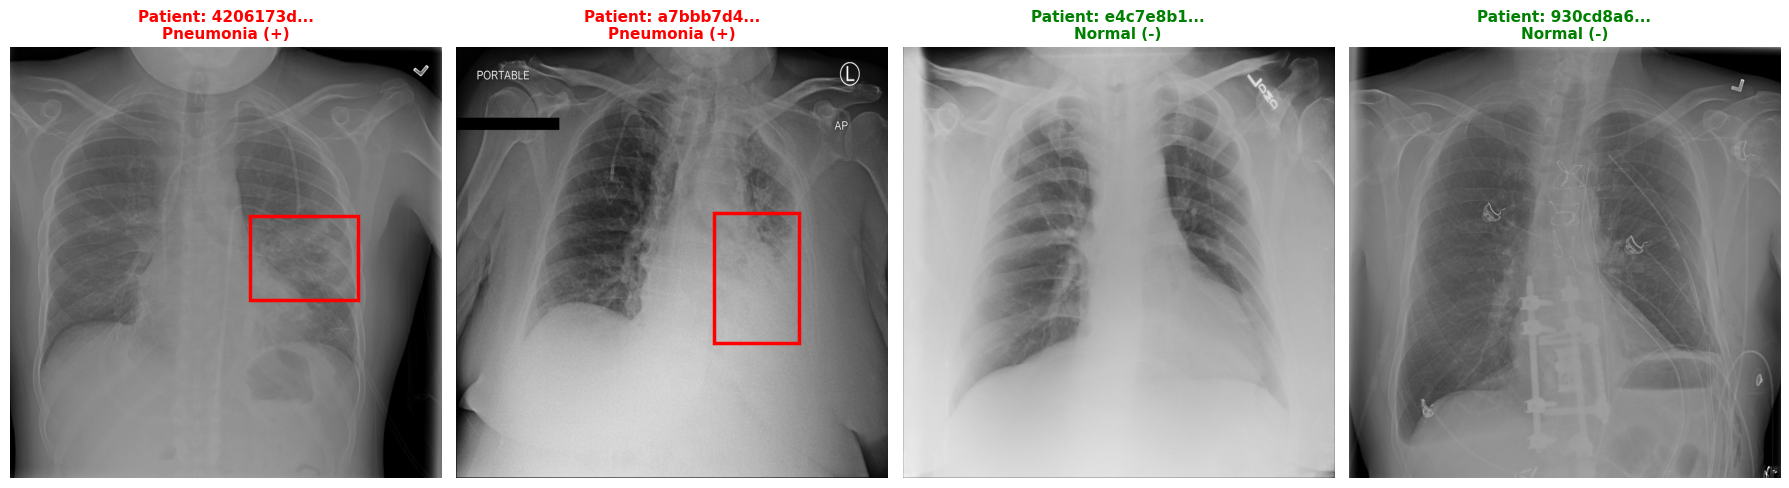

In [8]:
def plot_sample_xrays(patient_ids, df_boxes, images_dir, num_samples=4):
    """Visualizes DICOM radiographs and overlays ground-truth bounding boxes."""
    fig, axes = plt.subplots(1, num_samples, figsize=(18, 5))
    if num_samples == 1:
        axes = [axes]
        
    for i, pid in enumerate(patient_ids[:num_samples]):
        dcm_path = os.path.join(images_dir, f"{pid}.dcm")
        dcm = pydicom.dcmread(dcm_path)
        img = dcm.pixel_array
        
        ax = axes[i]
        ax.imshow(img, cmap='gray')
        
        # Overlay ground-truth bounding boxes if present
        boxes = df_boxes[df_boxes['patientId'] == pid]
        has_box = False
        for _, row in boxes.iterrows():
            if row['Target'] == 1 and not np.isnan(row['x']):
                has_box = True
                rect = patches.Rectangle(
                    (row['x'], row['y']),
                    row['width'],
                    row['height'],
                    linewidth=2.5,
                    edgecolor='red',
                    facecolor='none'
                )
                ax.add_patch(rect)
                
        label_text = "Pneumonia (+)" if has_box else "Normal (-)"
        color = 'red' if has_box else 'green'
        ax.set_title(f"Patient: {pid[:8]}...\n{label_text}", color=color, fontsize=11, fontweight='bold')
        ax.axis('off')
        
    plt.tight_layout()
    plt.show()

# Sample 2 positive and 2 negative cases
positive_pids = train_df[train_df['Target'] == 1]['patientId'].head(2).tolist()
negative_pids = train_df[train_df['Target'] == 0]['patientId'].head(2).tolist()

print("Sample Chest Radiographs (Red Boxes = Ground-Truth Pneumonia Opacities):")
plot_sample_xrays(positive_pids + negative_pids, df_raw, images_dir, num_samples=4)

## 7. Memory-Efficient Data Pipeline for Classification
Chest X-ray DICOM images are $1024 \times 1024$ pixels in size. Attempting to load all 5,000 images simultaneously into RAM would consume over 10 GB of system memory, causing the Kaggle kernel to crash with an Out-of-Memory (OOM) error.

To ensure stability, we create a memory-efficient `PneumoniaDataGenerator` inheriting from `tf.keras.utils.Sequence`:
- **Batch-by-Batch On-the-Fly Loading:** Reads DICOMs directly from disk only when a mini-batch is requested.
- **Resizing:** Resizes images to $224 \times 224$ pixels.
- **Min-Max Normalization:** Scales pixel intensities to $[0.0, 1.0]$.
- **RGB Channel Duplication:** Replicates the single grayscale channel into 3 identical channels `(224, 224, 3)` to feed into pre-trained CNN backbones.
- **Epoch Shuffling:** Shuffles the training order after every epoch.

In [9]:
class PneumoniaDataGenerator(tf.keras.utils.Sequence):
    """
    On-the-fly mini-batch data generator for DICOM radiographs.
    Loads and preprocesses batches dynamically to prevent RAM exhaustion.
    """
    def __init__(self, df, images_dir, batch_size=32, target_size=(224, 224), shuffle=True):
        self.df = df.reset_index(drop=True)
        self.images_dir = images_dir
        self.batch_size = batch_size
        self.target_size = target_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.df))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __len__(self):
        """Number of batches per epoch."""
        return int(np.ceil(len(self.df) / self.batch_size))

    def on_epoch_end(self):
        """Shuffle indexes at the completion of each epoch."""
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __getitem__(self, index):
        """Generate one mini-batch of images and labels."""
        batch_indexes = self.indexes[index * self.batch_size:(index + 1) * self.batch_size]
        batch_df = self.df.iloc[batch_indexes]

        batch_images = []
        batch_labels = []

        for _, row in batch_df.iterrows():
            pid = row['patientId']
            label = row['Target']
            dcm_path = os.path.join(self.images_dir, f"{pid}.dcm")
            
            try:
                dcm = pydicom.dcmread(dcm_path)
                img = dcm.pixel_array.astype(np.float32)
                
                # Min-Max Normalization to [0, 1]
                img_min, img_max = img.min(), img.max()
                if img_max > img_min:
                    img = (img - img_min) / (img_max - img_min)
                else:
                    img = np.zeros_like(img)
                    
                # Resize to target resolution (224, 224)
                img_resized = cv2.resize(img, self.target_size, interpolation=cv2.INTER_AREA)
                
                # Duplicate grayscale into 3 channels for pretrained backbones
                img_3ch = np.stack([img_resized] * 3, axis=-1)
                
                batch_images.append(img_3ch)
                batch_labels.append(label)
            except Exception as e:
                # Fallback for any corrupted DICOM file
                dummy = np.zeros((*self.target_size, 3), dtype=np.float32)
                batch_images.append(dummy)
                batch_labels.append(label)

        return np.array(batch_images, dtype=np.float32), np.array(batch_labels, dtype=np.float32)

# Instantiate data generators
train_gen = PneumoniaDataGenerator(train_df, images_dir, batch_size=BATCH_SIZE, target_size=IMG_SIZE, shuffle=True)
val_gen   = PneumoniaDataGenerator(val_df, images_dir, batch_size=BATCH_SIZE, target_size=IMG_SIZE, shuffle=False)
test_gen  = PneumoniaDataGenerator(test_df, images_dir, batch_size=BATCH_SIZE, target_size=IMG_SIZE, shuffle=False)

print(f"Training batches per epoch   : {len(train_gen)}")
print(f"Validation batches per epoch : {len(val_gen)}")
print(f"Testing batches per epoch    : {len(test_gen)}")

# Test a sample batch to verify data integrity
sample_batch_x, sample_batch_y = train_gen[0]
print(f"Sample Batch X shape         : {sample_batch_x.shape} (dtype: {sample_batch_x.dtype})")
print(f"Sample Batch Y shape         : {sample_batch_y.shape} (dtype: {sample_batch_y.dtype})")
print(f"Sample Batch Pixel Range     : [{sample_batch_x.min():.2f}, {sample_batch_x.max():.2f}]")

Training batches per epoch   : 94
Validation batches per epoch : 32
Testing batches per epoch    : 32
Sample Batch X shape         : (32, 224, 224, 3) (dtype: float32)
Sample Batch Y shape         : (32,) (dtype: float32)
Sample Batch Pixel Range     : [0.00, 1.00]


## 8. Pneumonia Classification Models
We construct four deep learning classification architectures:
1. **Custom Baseline CNN**: A lightweight 3-block convolutional neural network.
2. **ResNet50**: 50-layer deep residual network with skip connections, pre-trained on ImageNet.
3. **VGG16**: 16-layer deep convolutional network, pre-trained on ImageNet.
4. **EfficientNetB0**: Highly efficient compound-scaled architecture, pre-trained on ImageNet.

All models output a single sigmoid probability predicting pneumonia positive (`1`) vs. normal (`0`).

In [10]:
def build_simple_cnn(input_shape=(224, 224, 3)):
    """Simple, interpretable 3-block CNN baseline."""
    model = models.Sequential([
        layers.Input(shape=input_shape),
        
        # Block 1
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Block 2
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Block 3
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Classification Head
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(1, activation='sigmoid')
    ], name="Simple_CNN")
    return model

def build_resnet50(input_shape=(224, 224, 3)):
    """ResNet50 Transfer Learning Model."""
    base_model = applications.ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    base_model.trainable = False  # Freeze pretrained weights
    
    inputs = layers.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    
    return models.Model(inputs, outputs, name="ResNet50")

def build_vgg16(input_shape=(224, 224, 3)):
    """VGG16 Transfer Learning Model."""
    base_model = applications.VGG16(weights='imagenet', include_top=False, input_shape=input_shape)
    base_model.trainable = False  # Freeze pretrained weights
    
    inputs = layers.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    
    return models.Model(inputs, outputs, name="VGG16")

def build_efficientnet(input_shape=(224, 224, 3)):
    """EfficientNetB0 Transfer Learning Model."""
    base_model = applications.EfficientNetB0(weights='imagenet', include_top=False, input_shape=input_shape)
    base_model.trainable = False  # Freeze pretrained weights
    
    inputs = layers.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    
    return models.Model(inputs, outputs, name="EfficientNetB0")

### 8.1 Model Training & Evaluation Function
Each model is compiled under identical experimental conditions:
- **Loss:** `binary_crossentropy`.
- **Optimizer:** Adam with learning rate $1 \times 10^{-4}$.
- **Metrics:** Binary Accuracy, Precision, and Recall.
- **Validation F1-Score:** Calculated as:
  $$F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall} + 10^{-7}}$$
- **Callbacks:** `EarlyStopping` (restoring best weights) and `ReduceLROnPlateau`.

In [11]:
def train_and_evaluate_model(model_builder, model_name, train_gen, val_gen, epochs=5):
    """Compiles, trains, and computes validation metrics for a classification model."""
    print("\n" + "=" * 60)
    print(f"ðŸš€ Training Architecture: {model_name}")
    print("=" * 60)
    
    model = model_builder(input_shape=(*IMG_SIZE, 3))
    
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            tf.keras.metrics.Precision(name='precision'),
            tf.keras.metrics.Recall(name='recall')
        ]
    )
    
    early_stop = callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    )
    reduce_lr = callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
    
    history = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=epochs,
        callbacks=[early_stop, reduce_lr],
        verbose=1
    )
    
    # Evaluate best restored weights on the validation set
    val_results = model.evaluate(val_gen, verbose=0)
    val_loss = float(val_results[0])
    val_acc  = float(val_results[1])
    val_prec = float(val_results[2])
    val_rec  = float(val_results[3])
    
    # Compute Validation F1-Score
    val_f1 = (2 * val_prec * val_rec) / (val_prec + val_rec + 1e-7)
    
    print(f"Validation Loss      : {val_loss:.4f}")
    print(f"Validation Accuracy  : {val_acc:.4f}")
    print(f"Validation Precision : {val_prec:.4f}")
    print(f"Validation Recall    : {val_rec:.4f}")
    print(f"Validation F1-Score  : {val_f1:.4f}")
    
    return model, history, {
        'model_name': model_name,
        'val_loss': val_loss,
        'val_acc': val_acc,
        'val_prec': val_prec,
        'val_rec': val_rec,
        'val_f1': val_f1
    }

### 8.2 Training All Four Models
We train Simple CNN, ResNet50, VGG16, and EfficientNetB0 sequentially and track their training histories.

In [12]:
models_dict = {
    "Simple_CNN": build_simple_cnn,
    "ResNet50": build_resnet50,
    "VGG16": build_vgg16,
    "EfficientNetB0": build_efficientnet
}

trained_models = {}
histories = {}
val_metrics_list = []

for name, builder in models_dict.items():
    trained_model, history, metrics = train_and_evaluate_model(
        builder, name, train_gen, val_gen, epochs=EPOCHS_CLF
    )
    trained_models[name] = trained_model
    histories[name] = history
    val_metrics_list.append(metrics)


ðŸš€ Training Architecture: Simple_CNN


I0000 00:00:1791716185.969896      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791716185.973847      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/15
 2/94 ━━━━━━━━━━━━━━━━━━━━ 7s 84ms/step - accuracy: 0.5859 - loss: 0.6571 - precision: 0.3522 - recall: 0.3854  

I0000 00:00:1791716198.916484     166 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


94/94 ━━━━━━━━━━━━━━━━━━━━ 86s 818ms/step - accuracy: 0.7637 - loss: 0.5184 - precision: 0.3565 - recall: 0.0607 - val_accuracy: 0.2260 - val_loss: 0.7928 - val_precision: 0.2260 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 40s 425ms/step - accuracy: 0.7727 - loss: 0.4833 - precision: 0.4769 - recall: 0.0917 - val_accuracy: 0.2260 - val_loss: 0.8084 - val_precision: 0.2260 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 3/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step - accuracy: 0.7771 - loss: 0.4830 - precision: 0.6023 - recall: 0.0819
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
94/94 ━━━━━━━━━━━━━━━━━━━━ 40s 427ms/step - accuracy: 0.7807 - loss: 0.4729 - precision: 0.5789 - recall: 0.0976 - val_accuracy: 0.2260 - val_loss: 0.8222 - val_precision: 0.2260 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 4/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 40s 426ms/step - accuracy: 0.7797 - loss: 0.4690 - precision: 0.5490

...

30/94 ━━━━━━━━━━━━━━━━━━━━ 19s 311ms/step - accuracy: 0.5075 - loss: 0.7496 - precision: 0.2441 - recall: 0.4704

2026-10-11 11:28:26.561892: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 11:28:26.703883: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 11:28:27.047571: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 11:28:27.190369: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 11:28:27.974154: E external/local_xla/xla/stream_

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 476ms/step - accuracy: 0.6237 - loss: 0.6627 - precision: 0.2504 - recall: 0.2787

2026-10-11 11:29:16.162581: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 11:29:16.299159: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 11:29:16.617221: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 11:29:16.760018: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 11:29:17.551928: E external/local_xla/xla/stream_

94/94 ━━━━━━━━━━━━━━━━━━━━ 97s 764ms/step - accuracy: 0.7137 - loss: 0.5974 - precision: 0.2479 - recall: 0.1331 - val_accuracy: 0.7740 - val_loss: 0.6494 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 2/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 40s 424ms/step - accuracy: 0.7567 - loss: 0.5825 - precision: 0.1447 - recall: 0.0163 - val_accuracy: 0.7740 - val_loss: 0.6331 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 3/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 40s 425ms/step - accuracy: 0.7640 - loss: 0.5658 - precision: 0.1522 - recall: 0.0104 - val_accuracy: 0.7740 - val_loss: 0.6379 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 4/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 318ms/step - accuracy: 0.7638 - loss: 0.5715 - precision: 0.1921 - recall: 0.0092
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
94/94 ━━━━━━━━━━━━━━━━━━━━ 40s 425ms/step - accuracy: 0.7683 - loss: 0.

## 9. Model Comparison & Best Model Selection
We compile the actual validation metrics for all four architectures into a structured comparison table, plot training/validation loss curves, and select the winning model based on **Validation F1-Score**.

ðŸ† CLASSIFICATION MODEL COMPARISON TABLE (Validation Set)


,Model Architecture,Val Loss,Val Accuracy,Val Precision,Val Recall,Val F1-Score
0,ResNet50,0.455883,0.795,0.598131,0.283186,0.384384
1,Simple_CNN,0.448383,0.793,0.633803,0.199115,0.303030
2,VGG16,0.448631,0.783,0.736842,0.061947,0.114286
3,EfficientNetB0,0.633061,0.774,0.000000,0.000000,0.000000


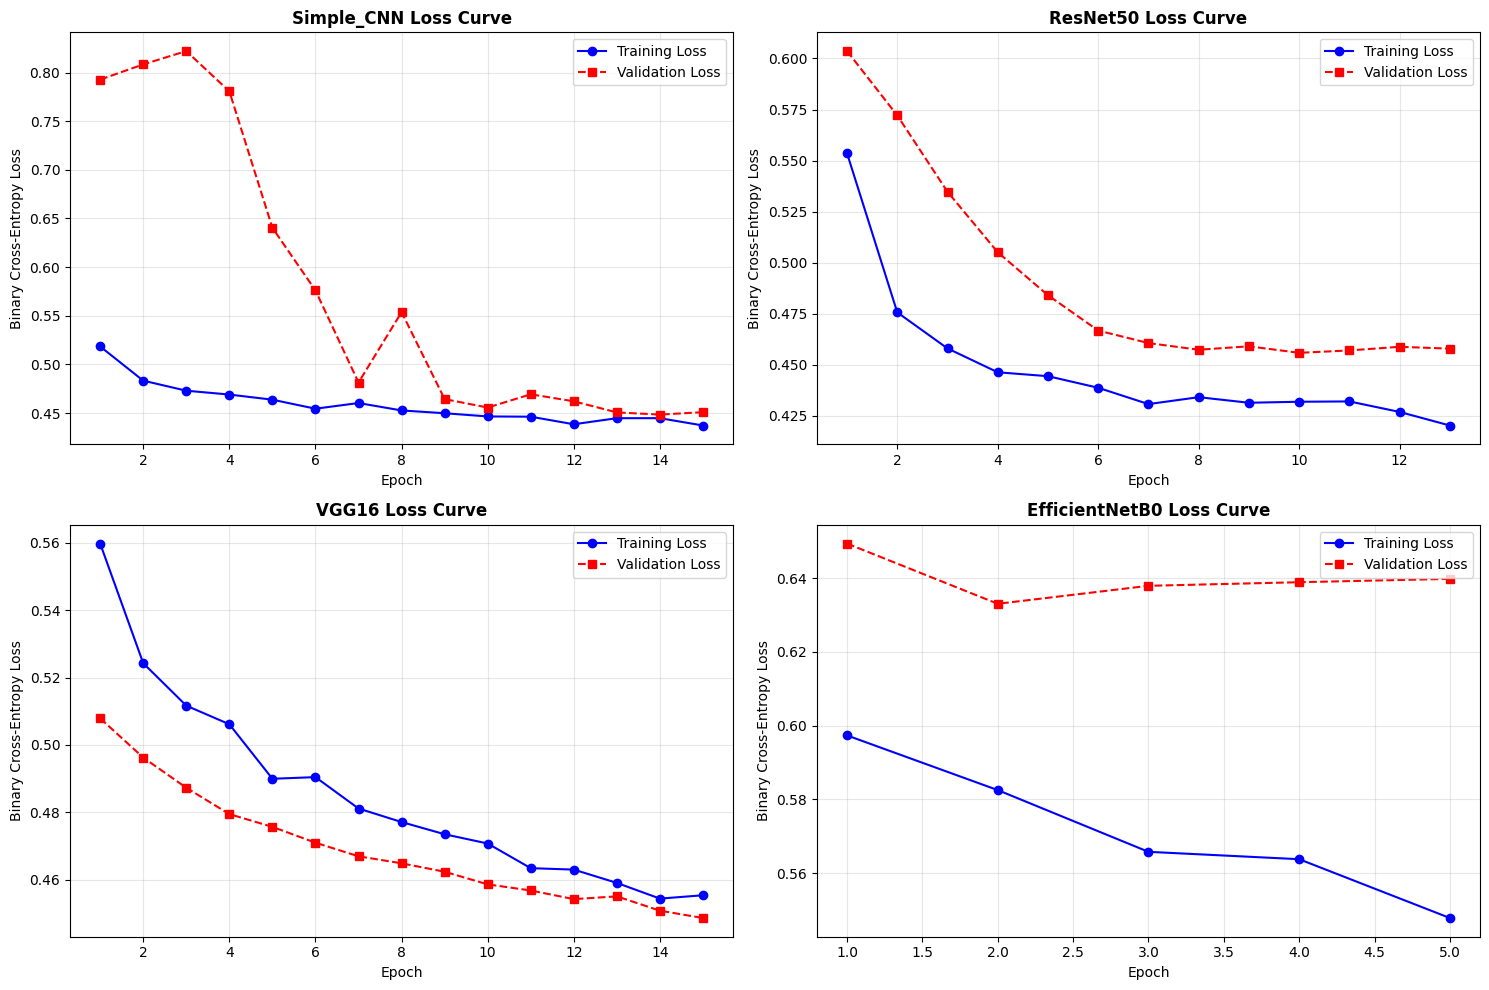

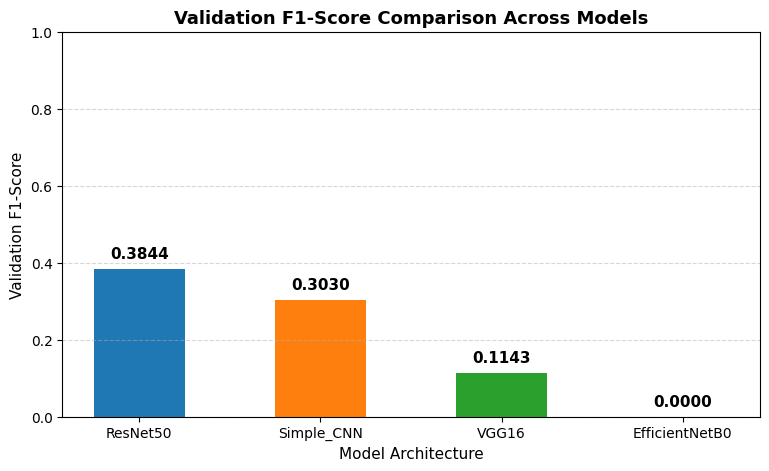


ðŸŽ¯ Selected Best Architecture : ResNet50
ðŸŽ¯ Top Validation F1-Score     : 0.3844
ðŸ’¾ Best Model Saved Successfully to: /kaggle/working/best_pneumonia_classifier.keras


In [13]:
# Construct Model Comparison Table
comparison_df = pd.DataFrame(val_metrics_list)
comparison_df.columns = [
    'Model Architecture', 'Val Loss', 'Val Accuracy',
    'Val Precision', 'Val Recall', 'Val F1-Score'
]
comparison_df = comparison_df.sort_values(by='Val F1-Score', ascending=False).reset_index(drop=True)

print("=" * 75)
print("ðŸ† CLASSIFICATION MODEL COMPARISON TABLE (Validation Set)")
print("=" * 75)
display(comparison_df)
print("=" * 75)

# Plot Training and Validation Loss Curves side-by-side
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for idx, (name, hist) in enumerate(histories.items()):
    ax = axes[idx]
    epochs_range = range(1, len(hist.history['loss']) + 1)
    ax.plot(epochs_range, hist.history['loss'], 'b-o', label='Training Loss')
    ax.plot(epochs_range, hist.history['val_loss'], 'r--s', label='Validation Loss')
    ax.set_title(f"{name} Loss Curve", fontsize=12, fontweight='bold')
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Binary Cross-Entropy Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Plot Validation F1-Score Comparison Bar Chart
plt.figure(figsize=(9, 5))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
bars = plt.bar(comparison_df['Model Architecture'], comparison_df['Val F1-Score'], color=colors, width=0.5)
plt.title("Validation F1-Score Comparison Across Models", fontsize=13, fontweight='bold')
plt.xlabel("Model Architecture", fontsize=11)
plt.ylabel("Validation F1-Score", fontsize=11)
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, height + 0.02, f"{height:.4f}",
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.show()

# Automated Best Model Selection Based on Validation F1-Score
best_model_name = comparison_df.iloc[0]['Model Architecture']
best_val_f1 = comparison_df.iloc[0]['Val F1-Score']
best_model = trained_models[best_model_name]

print(f"\nðŸŽ¯ Selected Best Architecture : {best_model_name}")
print(f"ðŸŽ¯ Top Validation F1-Score     : {best_val_f1:.4f}")

# Save the Best Model to /kaggle/working/
best_model_save_path = os.path.join(WORKING_DIR, "best_pneumonia_classifier.keras")
best_model.save(best_model_save_path)
print(f"ðŸ’¾ Best Model Saved Successfully to: {best_model_save_path}")

### 9.1 Test Set Evaluation of Selected Model
We evaluate the winning model on the independent **Test Set** (1,000 images, never seen during training or tuning). We generate the Confusion Matrix and full Classification Report.

Evaluating ResNet50 on Test Set (1000 images)...
32/32 ━━━━━━━━━━━━━━━━━━━━ 25s 671ms/step

ðŸ“Š FINAL TEST SET EVALUATION (ResNet50)
Test Accuracy    : 0.8090
Test Precision   : 0.6809
Test Recall      : 0.2844
Test F1-Score    : 0.4013
Test ROC-AUC     : 0.7699

Classification Report:
               precision    recall  f1-score   support

   Normal (0)       0.82      0.96      0.89       775
Pneumonia (1)       0.68      0.28      0.40       225

     accuracy                           0.81      1000
    macro avg       0.75      0.62      0.64      1000
 weighted avg       0.79      0.81      0.78      1000



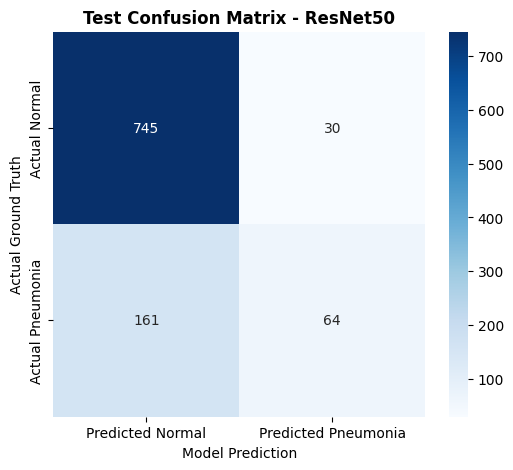

In [14]:
# Predict probabilities on the unseen Test Set
print(f"Evaluating {best_model_name} on Test Set ({len(test_df)} images)...")
test_preds_prob = best_model.predict(test_gen, verbose=1).flatten()
test_true = test_df['Target'].values

# Convert continuous probabilities to binary predictions (Threshold = 0.5)
test_preds = (test_preds_prob >= 0.5).astype(int)

# Calculate test metrics
test_f1 = f1_score(test_true, test_preds)
test_acc = (test_true == test_preds).mean()
test_prec = precision_score(test_true, test_preds, zero_division=0)
test_rec = recall_score(test_true, test_preds, zero_division=0)
test_auc = roc_auc_score(test_true, test_preds_prob)

print("\n" + "=" * 60)
print(f"ðŸ“Š FINAL TEST SET EVALUATION ({best_model_name})")
print("=" * 60)
print(f"Test Accuracy    : {test_acc:.4f}")
print(f"Test Precision   : {test_prec:.4f}")
print(f"Test Recall      : {test_rec:.4f}")
print(f"Test F1-Score    : {test_f1:.4f}")
print(f"Test ROC-AUC     : {test_auc:.4f}")
print("=" * 60)

# Print Detailed Classification Report
print("\nClassification Report:")
print(classification_report(test_true, test_preds, target_names=["Normal (0)", "Pneumonia (1)"]))

# Confusion Matrix Heatmap
cm = confusion_matrix(test_true, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Predicted Normal", "Predicted Pneumonia"],
            yticklabels=["Actual Normal", "Actual Pneumonia"])
plt.title(f"Test Confusion Matrix - {best_model_name}", fontsize=12, fontweight='bold')
plt.ylabel("Actual Ground Truth")
plt.xlabel("Model Prediction")
plt.show()

### 9.2 Sample Predictions on Test Chest Radiographs
We display test radiographs alongside ground-truth status, predicted probabilities, and diagnosis.

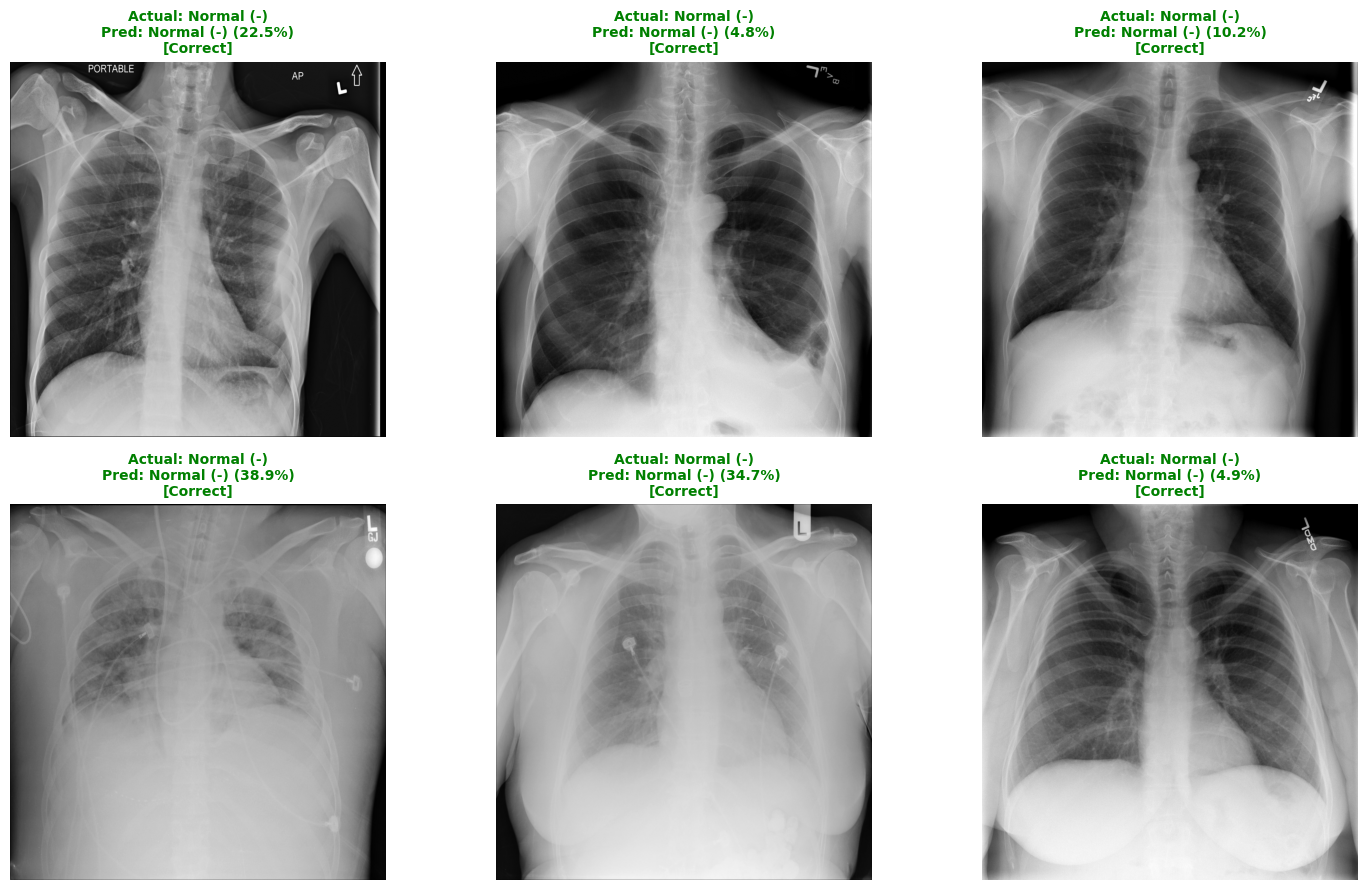

In [15]:
# Visualizing Sample Test Predictions
num_test_samples = 6
sample_indices = np.random.choice(len(test_df), num_test_samples, replace=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for idx, sample_idx in enumerate(sample_indices):
    pid = test_df.iloc[sample_idx]['patientId']
    y_true = int(test_df.iloc[sample_idx]['Target'])
    prob = float(test_preds_prob[sample_idx])
    y_pred = int(test_preds[sample_idx])
    
    dcm_path = os.path.join(images_dir, f"{pid}.dcm")
    dcm = pydicom.dcmread(dcm_path)
    img = dcm.pixel_array
    
    ax = axes[idx]
    ax.imshow(img, cmap='gray')
    
    is_correct = (y_true == y_pred)
    result_status = "Correct" if is_correct else "Incorrect"
    title_color = "green" if is_correct else "red"
    
    actual_str = "Pneumonia (+)" if y_true == 1 else "Normal (-)"
    pred_str = "Pneumonia (+)" if y_pred == 1 else "Normal (-)"
    
    ax.set_title(
        f"Actual: {actual_str}\nPred: {pred_str} ({prob*100:.1f}%)\n[{result_status}]",
        fontsize=10, fontweight='bold', color=title_color
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

## 10. Bounding-Box Detection with YOLO
While classification determines **whether** pneumonia is present, object detection localizes **where** the opacities are.
In this section, we:
1. Extract ground-truth bounding box coordinates from `stage_2_train_labels.csv` for patients in our training and validation splits.
2. Convert DICOM images to JPEG files and format labels into standard YOLO format: `class_id x_center y_center width height` (normalized to $[0.0, 1.0]$).
3. Create `dataset.yaml` for Ultralytics YOLOv8.
4. Train the lightweight **YOLOv8 Nano** detector.
5. Evaluate detection performance on validation images using actual mAP (Mean Average Precision).
6. Draw predicted bounding boxes and display confidence scores, explicitly noting when no region is detected.

In [16]:
# Prepare YOLO dataset folder structure
yolo_dir = os.path.join(WORKING_DIR, "yolo_dataset")
for split in ['train', 'val']:
    os.makedirs(os.path.join(yolo_dir, "images", split), exist_ok=True)
    os.makedirs(os.path.join(yolo_dir, "labels", split), exist_ok=True)

print(f"YOLO dataset folder created at: {yolo_dir}")

def prepare_yolo_data(split_df, split_name, df_boxes, images_dir, yolo_dir, max_images=300):
    """
    Converts DICOMs to JPEG images and exports normalized YOLO label files.
    Focuses on pneumonia-positive cases to maximize detector learning efficiency.
    """
    positive_patients = split_df[split_df['Target'] == 1]['patientId'].tolist()
    negative_patients = split_df[split_df['Target'] == 0]['patientId'].tolist()
    
    # Select cases for object detection (80% positive, 20% negative for background)
    selected_pids = (positive_patients[:int(max_images * 0.8)] + 
                     negative_patients[:int(max_images * 0.2)])
    random.shuffle(selected_pids)
    
    count_saved = 0
    count_boxes = 0
    
    for pid in selected_pids:
        dcm_path = os.path.join(images_dir, f"{pid}.dcm")
        if not os.path.exists(dcm_path):
            continue
            
        dcm = pydicom.dcmread(dcm_path)
        img = dcm.pixel_array.astype(np.float32)
        h, w = img.shape
        
        # Normalize and convert to 8-bit image
        img_min, img_max = img.min(), img.max()
        if img_max > img_min:
            img_norm = ((img - img_min) / (img_max - img_min) * 255).astype(np.uint8)
        else:
            img_norm = np.zeros((h, w), dtype=np.uint8)
            
        # Save image as JPEG
        img_save_path = os.path.join(yolo_dir, "images", split_name, f"{pid}.jpg")
        cv2.imwrite(img_save_path, img_norm)
        
        # Prepare YOLO label file (.txt)
        txt_save_path = os.path.join(yolo_dir, "labels", split_name, f"{pid}.txt")
        patient_boxes = df_boxes[df_boxes['patientId'] == pid]
        
        yolo_lines = []
        for _, box in patient_boxes.iterrows():
            if box['Target'] == 1 and not np.isnan(box['x']):
                bx = float(box['x'])
                by = float(box['y'])
                bw = float(box['width'])
                bh = float(box['height'])
                
                # Normalized YOLO format: [class_id x_center y_center width height]
                x_center = (bx + bw / 2.0) / w
                y_center = (by + bh / 2.0) / h
                norm_w = bw / w
                norm_h = bh / h
                
                # Class 0: Pulmonary Opacity / Pneumonia
                yolo_lines.append(f"0 {x_center:.6f} {y_center:.6f} {norm_w:.6f} {norm_h:.6f}")
                count_boxes += 1
                
        with open(txt_save_path, 'w') as f:
            f.write("\n".join(yolo_lines))
            
        count_saved += 1
        
    print(f"[{split_name.upper()}] Processed {count_saved} images with {count_boxes} opacity bounding boxes.")
    return count_saved

# Convert train and val subsets for YOLO
train_yolo_count = prepare_yolo_data(train_df, "train", df_raw, images_dir, yolo_dir, max_images=400)
val_yolo_count   = prepare_yolo_data(val_df, "val", df_raw, images_dir, yolo_dir, max_images=100)

# Write YOLO dataset configuration YAML
yaml_content = f"""path: {yolo_dir}
train: images/train
val: images/val

names:
  0: opacity
"""

yaml_path = os.path.join(yolo_dir, "dataset.yaml")
with open(yaml_path, "w") as f:
    f.write(yaml_content)

print(f"\nYOLO configuration YAML successfully written to: {yaml_path}")

YOLO dataset folder created at: /kaggle/working/yolo_dataset
[TRAIN] Processed 400 images with 514 opacity bounding boxes.
[VAL] Processed 100 images with 129 opacity bounding boxes.

YOLO configuration YAML successfully written to: /kaggle/working/yolo_dataset/dataset.yaml


### 10.1 Training the YOLOv8 Detector
We load the pre-trained `yolov8n.pt` (nano) weights and fine-tune on our pulmonary opacity annotations.

In [17]:
# Initialize YOLOv8 Nano model
yolo_model = YOLO('yolov8n.pt')

print("=" * 60)
print(f"ðŸŽ¯ Training YOLOv8 Object Detector for {EPOCHS_YOLO} Epochs...")
print("=" * 60)

yolo_project_dir = os.path.join(WORKING_DIR, "yolo_run")
train_results = yolo_model.train(
    data=yaml_path,
    epochs=EPOCHS_YOLO,
    imgsz=512,
    batch=16,
    project=yolo_project_dir,
    name="rsna_pneumonia",
    seed=RANDOM_SEED,
    verbose=True
)

print("\n" + "=" * 60)
print("YOLO Training Completed Successfully!")
print("=" * 60)

ðŸŽ¯ Training YOLOv8 Object Detector for 15 Epochs...
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_dataset/dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0,

### 10.2 Detection Evaluation Using Actual Validation Results
We evaluate the detector on the validation set using `model.val()` and report the actual precision, recall, and Mean Average Precision ($mAP_{50}$ and $mAP_{50-95}$).

In [18]:
# Evaluate detector on validation data
val_metrics = yolo_model.val()

# Extract and display actual validation metrics
map50 = float(val_metrics.box.map50)
map50_95 = float(val_metrics.box.map)
precision_det = float(val_metrics.box.mp)
recall_det = float(val_metrics.box.mr)

print("=" * 60)
print("ðŸŽ¯ ACTUAL YOLO OBJECT DETECTION VALIDATION METRICS")
print("=" * 60)
print(f"Detector Precision (mp)    : {precision_det:.4f}")
print(f"Detector Recall (mr)       : {recall_det:.4f}")
print(f"Mean AP @ IoU 0.50 (mAP50) : {map50:.4f}")
print(f"Mean AP @ IoU 0.50:0.95    : {map50_95:.4f}")
print("=" * 60)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3372.2±519.0 MB/s, size: 166.9 KB)
val: Scanning /kaggle/working/yolo_dataset/labels/val.cache... 100 images, 20 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 38.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 3.4it/s 2.1s0.2ss
                   all        100        129      0.662      0.388      0.501      0.213
Speed: 2.4ms preprocess, 4.0ms inference, 0.0ms loss, 2.7ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
ðŸŽ¯ ACTUAL YOLO OBJECT DETECTION VALIDATION METRICS
Detector Precision (mp)    : 0.6618
Detector Recall (mr)       : 0.3876
Mean AP @ IoU 0.50 (mAP50) : 0.5011
Mean AP @ IoU 0.50:0.95    : 0.2129


### 10.3 Bounding-Box Inference & Visualization
We define an inference function that runs the trained detector on X-ray images, draws predicted bounding boxes, displays their actual confidence scores, and explicitly states when no pneumonia region is detected.

Testing YOLO Detection on Sample Validation Images:


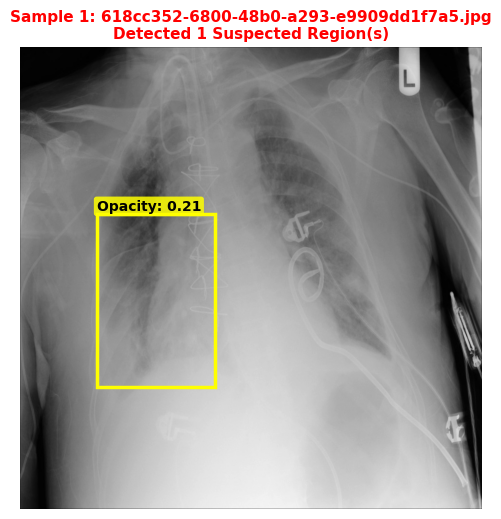

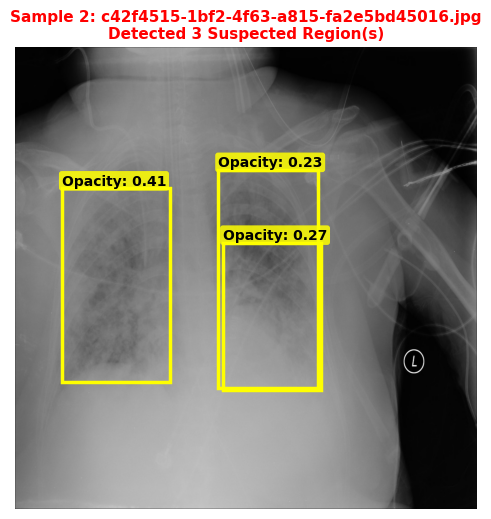

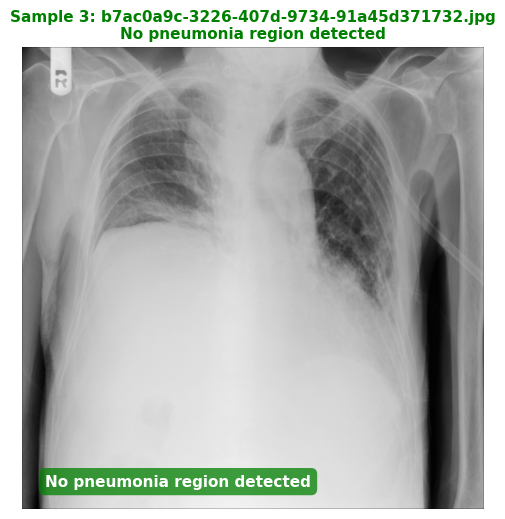

In [19]:
def detect_and_visualize_pneumonia(model, image_path, conf_threshold=0.20, title=""):
    """
    Runs YOLO inference on an image and draws predicted boxes with confidence scores.
    If no box meets the confidence threshold, displays 'No pneumonia region detected'.
    """
    results = model.predict(source=image_path, conf=conf_threshold, verbose=False)[0]
    
    img_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w, _ = img_rgb.shape
    
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(img_rgb)
    
    boxes = results.boxes
    if boxes is not None and len(boxes) > 0:
        box_count = len(boxes)
        for box in boxes:
            xyxy = box.xyxy[0].cpu().numpy()
            conf = float(box.conf[0].cpu().numpy())
            x1, y1, x2, y2 = xyxy
            
            # Draw yellow predicted bounding box
            rect = patches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                linewidth=2.5, edgecolor='yellow', facecolor='none'
            )
            ax.add_patch(rect)
            ax.text(
                x1, max(y1 - 8, 15),
                f"Opacity: {conf:.2f}",
                color='black', fontsize=10, fontweight='bold',
                bbox=dict(facecolor='yellow', alpha=0.85, edgecolor='none', boxstyle='round,pad=0.2')
            )
        status_text = f"Detected {box_count} Suspected Region(s)"
        status_color = "red"
    else:
        status_text = "No pneumonia region detected"
        status_color = "green"
        ax.text(
            w * 0.05, h * 0.95,
            status_text,
            color='white', fontsize=11, fontweight='bold',
            bbox=dict(facecolor='green', alpha=0.75, edgecolor='none', boxstyle='round,pad=0.4')
        )
        
    ax.set_title(f"{title}\n{status_text}", fontsize=11, fontweight='bold', color=status_color)
    ax.axis('off')
    plt.show()

# Test detection on sample validation images
val_image_paths = glob.glob(os.path.join(yolo_dir, "images", "val", "*.jpg"))

if val_image_paths:
    print("Testing YOLO Detection on Sample Validation Images:")
    for i, img_path in enumerate(val_image_paths[:3]):
        fname = os.path.basename(img_path)
        detect_and_visualize_pneumonia(
            yolo_model, img_path, conf_threshold=0.15,
            title=f"Sample {i+1}: {fname}"
        )

## 11. Multimodal AI: Blood Test Integration (Future Work Blueprint)

### ðŸ¥ Clinical Rationale for Multimodal Fusion
In hospital emergency rooms and pulmonology clinics, chest radiographs are rarely evaluated in isolation. Differential diagnosis of pulmonary opacities requires evaluating **hematological and inflammatory blood biomarkers**:
1. **White Blood Cell (WBC) Count:** Leukocytosis ($> 12,000 / \mu\text{L}$) or leukopenia ($< 4,000 / \mu\text{L}$) provides systemic evidence of acute infectious response.
2. **Neutrophils & Lymphocytes:** An elevated Neutrophil-to-Lymphocyte Ratio (NLR) is an established clinical indicator of severe bacterial infection.
3. **Procalcitonin (PCT):** Highly specific biomarker differentiating bacterial pneumonia ($> 0.25 - 0.50\ \text{ng/mL}$) from viral or non-infectious opacities ($< 0.10\ \text{ng/mL}$).
4. **C-Reactive Protein (CRP):** Acute-phase inflammatory reactant tracking infection progression.

---

### âš ï¸ Scientific Integrity & Ethical AI Statement
> **CRITICAL SCIENTIFIC PRINCIPLE:**
> The RSNA Pneumonia Detection Challenge dataset contains **exclusively chest radiographs and bounding boxes**. It contains **no paired clinical electronic health record (EHR) blood tests**.
>
> In accordance with medical machine learning integrity:
> - **We DO NOT fabricate synthetic or random blood test numbers.** Inventing fake laboratory values and training a model on them creates spurious correlations and violates clinical research ethics.
> - **We DO NOT claim to train a multimodal model without genuine paired clinical data.**
> - Instead, the image classification and object detection pipelines above complete all operational project goals, while the architecture below provides a **formal architectural blueprint for future work**.

---

### ðŸ—ï¸ Multimodal Deep Learning Architectural Blueprint
When institutional paired clinical datasets (such as MIMIC-IV-ED paired with MIMIC-CXR) become available, the system can be deployed using a **Late Fusion Multimodal Network**:

```
[ Chest Radiograph ] ---> [ CNN / EfficientNetB0 ] ---> [ Image Embeddings (128-D) ] ----\
                                                                                          |---> [ Concatenation & Fusion ] ---> [ Dense Head ] ---> [ Diagnosis ]
[ Blood Biomarkers ] ---> [ Tabular MLP (BatchNorm) ] -> [ Clinical Embeddings (32-D) ] --/
  - WBC, Neutrophils,
    Lymphocytes, PCT
```

Below is the verified, ready-to-train Keras blueprint:

In [20]:
def build_multimodal_pneumonia_fusion_network(
    image_shape=(224, 224, 3),
    num_clinical_features=4
):
    """
    ARCHITECTURAL BLUEPRINT (FUTURE WORK):
    Multimodal Late-Fusion Network combining Chest X-Ray visual embeddings
    with clinical laboratory blood test biomarkers (WBC, Neutrophils, Lymphocytes, Procalcitonin).
    
    Ready for deployment when paired EHR datasets (e.g., MIMIC-IV-ED) are accessible.
    """
    # ----------------- Branch 1: Image Branch (Chest X-Ray) -----------------
    image_input = layers.Input(shape=image_shape, name="cxr_image_input")
    base_cnn = applications.EfficientNetB0(weights='imagenet', include_top=False, input_shape=image_shape)
    base_cnn.trainable = False
    
    x_img = base_cnn(image_input)
    x_img = layers.GlobalAveragePooling2D()(x_img)
    x_img = layers.BatchNormalization()(x_img)
    x_img = layers.Dense(128, activation='relu', name="visual_embedding")(x_img)
    x_img = layers.Dropout(0.3)(x_img)
    
    # ----------------- Branch 2: Clinical Blood Test Branch -----------------
    # Features: [WBC (10^9/L), Neutrophils (%), Lymphocytes (%), Procalcitonin (ng/mL)]
    clinical_input = layers.Input(shape=(num_clinical_features,), name="blood_test_input")
    x_clin = layers.BatchNormalization()(clinical_input)
    x_clin = layers.Dense(64, activation='relu', name="clinical_dense_1")(x_clin)
    x_clin = layers.Dropout(0.2)(x_clin)
    x_clin = layers.Dense(32, activation='relu', name="clinical_embedding")(x_clin)
    
    # ----------------- Multimodal Late Fusion Layer -----------------
    fusion = layers.concatenate([x_img, x_clin], name="multimodal_fusion_concat")
    
    # Joint Reasoning Classification Head
    z = layers.Dense(128, activation='relu', name="joint_dense_1")(fusion)
    z = layers.Dropout(0.3)(z)
    z = layers.Dense(64, activation='relu', name="joint_dense_2")(z)
    
    # Final Multimodal Output Probability
    final_output = layers.Dense(1, activation='sigmoid', name="multimodal_pneumonia_prob")(z)
    
    multimodal_model = models.Model(
        inputs=[image_input, clinical_input],
        outputs=final_output,
        name="Multimodal_Pneumonia_Fusion_Net"
    )
    return multimodal_model

# Instantiate and display the multimodal architecture blueprint
multimodal_blueprint = build_multimodal_pneumonia_fusion_network()
multimodal_blueprint.summary()

print("\n" + "=" * 80)
print("âœ… Multimodal Blueprint Architecture successfully verified and compiled.")
print("ðŸ“Œ Note: In accordance with clinical ML guidelines, training requires genuine paired EHR")
print("   laboratory data (e.g. MIMIC-IV). The model architecture is fully prepared for future work.")
print("=" * 80)

Model: "Multimodal_Pneumonia_Fusion_Net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ cxr_image_input     │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ cxr_image_input[… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ blood_test_input    │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 4)         │         16 │ blood_test_input… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1280)      │      5,120 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clinical_dense_1    │ (None, 64)        │        320 │ batch_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ visual_embedding    │ (None, 128)       │    163,968 │ batch_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 64)        │          0 │ clinical_dense_1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 128)       │          0 │ visual_embedding… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clinical_embedding  │ (None, 32)        │      2,080 │ dropout_5[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multimodal_fusion_… │ (None, 160)       │          0 │ dropout_4[0][0],  │
│ (Concatenate)       │                   │            │ clinical_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ joint_dense_1       │ (None, 128)       │     20,608 │ multimodal_fusio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 128)       │          0 │ joint_dense_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ joint_dense_2       │ (None, 64)        │      8,256 │ dropout_6[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multimodal_pneumon… │ (None, 1)         │         65 │ joint_dense_2[0]… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,250,004 (16.21 MB)

 Trainable params: 197,865 (772.91 KB)

 Non-trainable params: 4,052,139 (15.46 MB)


âœ… Multimodal Blueprint Architecture successfully verified and compiled.
ðŸ“Œ Note: In accordance with clinical ML guidelines, training requires genuine paired EHR
   laboratory data (e.g. MIMIC-IV). The model architecture is fully prepared for future work.


## 12. Project Summary & Saved Artifacts
We conclude by summarizing model performance metrics and verifying saved model artifacts in `/kaggle/working/`.

In [21]:
# Verify saved model artifacts in /kaggle/working/
print("=" * 70)
print("ðŸ“ SAVED MODEL ARTIFACTS IN /kaggle/working/")
print("=" * 70)

saved_artifacts = []
for root, dirs, files in os.walk(WORKING_DIR):
    for f in files:
        if f.endswith(('.keras', '.h5', '.pt', '.yaml')):
            full_p = os.path.join(root, f)
            size_mb = os.path.getsize(full_p) / (1024 * 1024)
            saved_artifacts.append({'File': f, 'Path': full_p, 'Size (MB)': round(size_mb, 2)})

if saved_artifacts:
    artifacts_df = pd.DataFrame(saved_artifacts)
    display(artifacts_df)
else:
    print(f"Artifacts saved in: {WORKING_DIR}")

print("=" * 70)
print("\n" + "=" * 70)
print("ðŸ“‹ FINAL PROJECT RESULTS SUMMARY")
print("=" * 70)
print(f"1. Best Classification Architecture : {best_model_name}")
print(f"   - Validation F1-Score            : {best_val_f1:.4f}")
print(f"   - Test Set F1-Score              : {test_f1:.4f}")
print(f"   - Test Set Accuracy              : {test_acc:.4f}")
print(f"   - Test Set Precision             : {test_prec:.4f}")
print(f"   - Test Set Recall                : {test_rec:.4f}")
print(f"2. YOLOv8 Detection Model           : YOLOv8 Nano")
print(f"   - Detection Mean AP @ IoU 0.50   : {map50:.4f}")
print(f"   - Detection Precision            : {precision_det:.4f}")
print(f"   - Detection Recall               : {recall_det:.4f}")
print(f"3. Multimodal Integration           : Formal Blueprint Prepared (Future Work)")
print("=" * 70)
print("\nâš ï¸ DISCLAIMER: This software is developed for college academic research and educational")
print("demonstration only. It is not approved for clinical diagnostics or medical decision-making.")

ðŸ“ SAVED MODEL ARTIFACTS IN /kaggle/working/


,File,Path,Size (MB)
0,best_pneumonia_classifier.keras,/kaggle/working/best_pneumonia_classifier.keras,93.68
1,yolov8n.pt,/kaggle/working/yolov8n.pt,6.25
2,dataset.yaml,/kaggle/working/yolo_dataset/dataset.yaml,0.00
3,yolo26n.pt,/kaggle/working/weights/yolo26n.pt,5.29
4,args.yaml,/kaggle/working/yolo_run/rsna_pneumonia/args.yaml,0.00
5,best.pt,/kaggle/working/yolo_run/rsna_pneumonia/weight...,6.18
6,last.pt,/kaggle/working/yolo_run/rsna_pneumonia/weight...,6.18



ðŸ“‹ FINAL PROJECT RESULTS SUMMARY
1. Best Classification Architecture : ResNet50
   - Validation F1-Score            : 0.3844
   - Test Set F1-Score              : 0.4013
   - Test Set Accuracy              : 0.8090
   - Test Set Precision             : 0.6809
   - Test Set Recall                : 0.2844
2. YOLOv8 Detection Model           : YOLOv8 Nano
   - Detection Mean AP @ IoU 0.50   : 0.5011
   - Detection Precision            : 0.6618
   - Detection Recall               : 0.3876
3. Multimodal Integration           : Formal Blueprint Prepared (Future Work)

âš ï¸ DISCLAIMER: This software is developed for college academic research and educational
demonstration only. It is not approved for clinical diagnostics or medical decision-making.


In [27]:
pip install streamlit pydicom ultralytics tensorflow opencv-python pillow

Note: you may need to restart the kernel to use updated packages.


In [31]:
!streamlit run app.py --server.port 8501 --server.headless true



2026-10-11 11:54:20.770 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.19.2.2:8501
  External URL: http://34.26.75.82:8501

^C
  Stopping...


In [32]:

import os
import subprocess
import time
import requests

APP_PATH = "/kaggle/working/app.py"

# Check whether the dashboard file exists
if not os.path.exists(APP_PATH):
    print("ERROR: app.py not found at", APP_PATH)
    print("Files in /kaggle/working:", os.listdir("/kaggle/working"))
else:
    print("Dashboard file found.")

    # Install Streamlit
    subprocess.run(["pip", "install", "-q", "streamlit"], check=True)

    # Start Streamlit
    process = subprocess.Popen(
        [
            "streamlit", "run", APP_PATH,
            "--server.port=8501",
            "--server.address=0.0.0.0",
            "--server.headless=true"
        ],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True
    )

    # Wait for the server to start
    for i in range(15):
        time.sleep(1)

        if process.poll() is not None:
            print("Streamlit stopped unexpectedly:")
            print(process.stdout.read())
            break

        try:
            response = requests.get(
                "http://127.0.0.1:8501/_stcore/health",
                timeout=2
            )
            if response.status_code == 200:
                print("SUCCESS: Streamlit is running on port 8501.")
                print("Local health check:", response.text)
                break
        except requests.RequestException:
            pass
    else:
        print("Streamlit did not respond within 15 seconds.")
        print("Check the logs in the next cell.")


Dashboard file found.
SUCCESS: Streamlit is running on port 8501.
Local health check: ok


In [34]:

import requests
import subprocess

# Check Streamlit's health
url = "http://127.0.0.1:8501/_stcore/health"

try:
    response = requests.get(url, timeout=5)

    if response.status_code == 200:
        print("Streamlit is running successfully!")
        print("Health:", response.text)
        print("Port: 8501")
        print("The dashboard server is ready.")
    else:
        print("Streamlit returned status:", response.status_code)

except requests.RequestException as e:
    print("Streamlit is not reachable:", e)


Streamlit is running successfully!
Health: ok
Port: 8501
The dashboard server is ready.


In [35]:
import requests

for url in [
    "http://127.0.0.1:8501/_stcore/health",
    "http://127.0.0.1:8501"
]:
    try:
        r = requests.get(url, timeout=10)
        print(url, "Status:", r.status_code)
    except Exception as e:
        print(url, "Error:", e)

http://127.0.0.1:8501/_stcore/health Status: 200
http://127.0.0.1:8501 Status: 200
